# Growth Sequential — Kernel

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from nlls_gram import RepeatedFactorMetric, RidgeLevenbergMarquardt

Structural parameters: the Aruoba–Fernández-Villaverde–Rubio-Ramírez
calibration, with the continuous discount rate mapped from the quarterly
anchor $e^{-\hat\rho/4} = \beta$. The dict `p` is the solver’s
differentiable-parameter pytree —
[`nlls-gram`](https://pypi.org/project/nlls-gram/) differentiates the
solve implicitly with respect to every leaf, the initial condition $k_0$
included.

In [2]:
a = 1.0 / 3.0  # capital share in f(k) = k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
k_0 = 1.0  # initial capital
p = {"a": a, "delta": delta, "rho_hat": rho_hat, "sigma_crra": sigma_crra, "k_0": k_0}

Parameters of the algorithm: the kernel hyperparameters, the collocation
and test grids, and the ridge Levenberg–Marquardt settings.

In [3]:
ELL = 10.0  # Matern-1/2 length scale
SIGMA = 1.0  # kernel amplitude
TRAIN_T = 100.0
N_TRAIN = 101
TEST_T = 110.0
N_TEST = 100
TVC_T = 200.0
RIDGE = 1e-10  # disappearing penalty weight
ATOL = 2e-8  # on the 1/sqrt(3n)-scaled residual norm
GTOL = 1e-9
MAX_STEPS = 50

t_train = jnp.linspace(0.0, TRAIN_T, N_TRAIN)
t_test = jnp.linspace(0.0, TEST_T, N_TEST)

## The model

A planner chooses consumption to maximize discounted CRRA utility
subject to capital accumulation,

$$\max_{c(t)} \int_0^\infty e^{-\hat\rho t}\, \frac{c(t)^{1-\sigma}}{1-\sigma}\, dt
\quad \text{s.t.} \quad
k'(t) = k(t)^a - \delta k(t) - c(t), \qquad k(0) = k_0.$$

Pontryagin’s conditions introduce the costate $\mu$ (the shadow price of
capital) and give three functional equations,

$$k'(t) = k(t)^a - \delta k(t) - c(t),
\qquad
\mu'(t) = -\mu(t)\big(a\, k(t)^{a-1} - \delta - \hat\rho\big),
\qquad
\mu(t) = c(t)^{-\sigma},$$

a system with a one-dimensional family of solutions indexed by $c(0)$:
only the saddle path also satisfies the transversality condition
$\lim_{t\to\infty} e^{-\hat\rho t} \mu(t)\, k(t) = 0$. As in the
asset-pricing example, we impose **no terminal condition** — $c(0)$ and
$\mu(0)$ are free unknowns and the minimum-norm selection picks the
saddle path, with transversality verified after the fact.

## The integrated kernel

Each of the three paths $(\mu, c, k)$ is an integrated-kernel expansion
built from the Matérn-1/2 kernel

$$k(t, t') = \sigma^2 e^{-|t - t'|/\ell},
\qquad
h(d) = \sigma^2 \ell \left(1 - e^{-d/\ell}\right),
\qquad
\tilde K(t_i, t_j) = h(t_j) + \operatorname{sign}(t_i - t_j)\, h(|t_i - t_j|),$$

so that each path and its derivative are, exactly,

$$x(t) = x(0) + \sum_j \alpha_j \tilde K(t, t_j),
\qquad
x'(t) = \sum_j \alpha_j k(t, t_j).$$

Since $\tilde K(0, \cdot) = 0$, the capital path is pinned at
$k(0) = k_0$ from `p`, while $c(0)$ and $\mu(0)$ ride in `theta` as free
scalars.

In [4]:
def antiderivative(d):
    return SIGMA**2 * ELL * (1.0 - jnp.exp(-d / ELL))


def kernel_matrices(t_i, t_j):
    s = t_i[:, None] - t_j[None, :]
    K = SIGMA**2 * jnp.exp(-jnp.abs(s) / ELL)
    K_tilde = antiderivative(t_j)[None, :] + jnp.sign(s) * antiderivative(jnp.abs(s))
    return K, K_tilde


def paths(theta, K, K_tilde, p):
    mu = theta["mu_0"] + K_tilde @ theta["alpha_mu"]
    dmu_dt = K @ theta["alpha_mu"]
    c = theta["c_0"] + K_tilde @ theta["alpha_c"]
    k = p["k_0"] + K_tilde @ theta["alpha_k"]
    dk_dt = K @ theta["alpha_k"]
    return mu, dmu_dt, c, k, dk_dt

## Ridgeless least squares

Stacking the three residuals on the training grid — with the first-order
condition in the multiplicative form $\mu c^\sigma - 1 = 0$ — gives a
least-squares problem with a *disappearing penalty* over the summed RKHS
norms,

$$\min_{\theta}\ \| r(\theta) \|^2
+ \lambda \left( \alpha_\mu^\top K \alpha_\mu + \alpha_c^\top K \alpha_c + \alpha_k^\top K \alpha_k \right),
\qquad
r(\theta) = \frac{1}{\sqrt{3n}}
\begin{bmatrix}
k' - \big(k^a - \delta k - c\big) \\
\mu' + \mu \big(a k^{a-1} - \delta - \hat\rho\big) \\
\mu c^{\sigma} - 1
\end{bmatrix}.$$

As $\lambda \to 0$ the minimizer converges to the interpolant of minimal
summed norm with the free scalars $(c_0, \mu_0)$ unpenalized; we pin
$\lambda$ tiny and fixed (`RIDGE`). The paths that violate
transversality over-accumulate capital toward the consumption-free
maximum — far steeper, hence far larger norm — so the minimum-norm
interpolant is the saddle path.

In [5]:
def residuals(theta, K, K_tilde, p):
    mu, dmu_dt, c, k, dk_dt = paths(theta, K, K_tilde, p)
    resource = dk_dt - (k ** p["a"] - p["delta"] * k - c)
    costate = dmu_dt + mu * (p["a"] * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
    foc = mu * c ** p["sigma_crra"] - 1.0
    return resource, costate, foc


def residual_fn(theta, args, p):
    resource, costate, foc = residuals(theta, args["K"], args["K_tilde"], p)
    residual = jnp.concatenate([resource, costate, foc])
    return residual / jnp.sqrt(residual.size)

## Solve

The three paths share one Gram matrix, so the penalty is a
`RepeatedFactorMetric` holding its upper Cholesky factor with
`repeats=3`: it penalizes the three leading blocks of the flattened
`theta` — dicts flatten by sorted key, so the `"alpha_*"` keys lead —
and leaves the trailing $(c_0, \mu_0)$ as the unpenalized free block.
The free scalars warm-start at the flat steady-flow guess
$c(0) = k_0^a - \delta k_0$, $\mu(0) = c(0)^{-\sigma}$; convergence
requires both the gradient (`gtol`) and residual (`atol`) tests.

In [6]:
K, K_tilde = kernel_matrices(t_train, t_train)
metric = RepeatedFactorMetric(jnp.linalg.cholesky(K, upper=True), repeats=3)
args = {"K": K, "K_tilde": K_tilde}

c_flow = k_0**a - delta * k_0  # flat steady-flow warm start
# Flattened by sorted key: the "alpha_*" blocks (penalized by the metric)
# precede the free scalars ("c_0", "mu_0").
theta_0 = {
    "alpha_mu": jnp.zeros(N_TRAIN),
    "alpha_c": jnp.zeros(N_TRAIN),
    "alpha_k": jnp.zeros(N_TRAIN),
    "c_0": jnp.asarray(c_flow),
    "mu_0": jnp.asarray(c_flow**-sigma_crra),
}

solver = RidgeLevenbergMarquardt(residual_fn, metric=metric, ridge=RIDGE)
start = time.perf_counter()
result = solver.solve(
    theta_0,
    args,
    p=p,
    max_steps=MAX_STEPS,
    atol=ATOL,
    gtol=GTOL,
    max_steps_is_success=False,
)
solve_time = time.perf_counter() - start
theta = result.x

## Results

Off-grid evaluation only needs fresh cross-kernel matrices against the
training dates; the test grid extends past the training horizon to check
extrapolation. The transversality certificate evaluates
$-\hat\rho T - \sigma \log c(T) + \log k(T)$ — the logarithm of
$e^{-\hat\rho T} \mu(T) k(T)$ under the first-order condition — at
$T = 200$: on the saddle path it sits far below zero, on a capital
bubble it turns positive.

In [7]:
K_test, K_tilde_test = kernel_matrices(t_test, t_train)
_, costate_test, _ = residuals(theta, K_test, K_tilde_test, p)

# Log transversality certificate at T: -rho_hat T - sigma log c(T) + log k(T).
K_tvc, K_tilde_tvc = kernel_matrices(jnp.array([TVC_T]), t_train)
_, _, c_T, k_T, _ = paths(theta, K_tvc, K_tilde_tvc, p)
log_tvc = -rho_hat * TVC_T - sigma_crra * jnp.log(c_T[0]) + jnp.log(k_T[0])

print(f"solve: {int(result.steps)} steps in {solve_time:.2f}s (incl. jit)")
print(f"c_0 = {float(theta["c_0"]):.6f}, mu_0 = {float(theta["mu_0"]):.6f}")
print(f"mean |Euler residual| test: {float(jnp.abs(costate_test).mean()):.3e}")
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: 18 steps in 0.39s (incl. jit)
c_0 = 0.669717, mu_0 = 2.229553
mean |Euler residual| test: 7.562e-05
log-TVC at t=200: -7.4   (should be << 0)

Capital rises from $k_0$ toward its steady state while consumption
climbs to its own; the costate (Euler) residual sits on zero inside the
training horizon (dotted) and degrades gracefully past it.

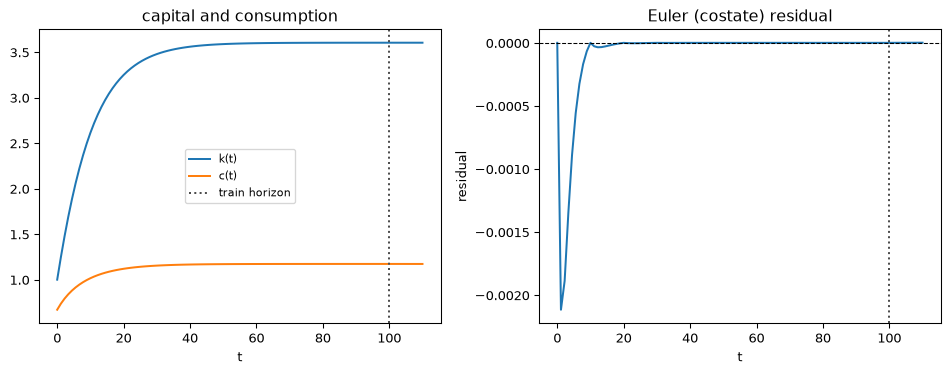

In [8]:
_, _, c_test, k_test, _ = paths(theta, K_test, K_tilde_test, p)

fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.plot(t_test, k_test, "C0", label="k(t)")
ax_k.plot(t_test, c_test, "C1", label="c(t)")
ax_k.axvline(TRAIN_T, color="0.3", linestyle=":", label="train horizon")
ax_k.set(xlabel="t", title="capital and consumption")
ax_k.legend(fontsize=8)
ax_r.plot(t_test, costate_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.axvline(TRAIN_T, color="0.3", linestyle=":")
ax_r.set(xlabel="t", ylabel="residual", title="Euler (costate) residual")
fig.tight_layout()
plt.show()